## 13. Does a model trained at one monitoring station work at a station in a different tributary, or does each station need its own model?

### 13.1 Approach, data, and features

I evaluated whether dissolved oxygen forecasting models transfer between **Aquarium East Bottom (AEB, Patapsco River)** and **Mataponi (MTI, Patuxent River)**. I tested both transfer directions at 1-, 3-, 6-, 12-, and 24-hour forecast leads, comparing three approaches:

1. **Transferred:** fit and tune at one station, then apply the frozen model at the other station.
2. **Local:** fit and tune on the receiving station's earlier observations.
3. **Persistence:** use the receiving station's current DO as the future prediction.

The target is future dissolved oxygen, **DO(t + h), in mg/L**. The regressors learn the change from current DO; I add the receiving station's current DO back to produce the forecast. This requires current and historical measurements at the receiving station. It does not predict at a station with no sensor history.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

q2_eda = Path.cwd() if (Path.cwd() / 'Station_Transfer').is_dir() else Path.cwd() / 'EDA'
q2_folder = q2_eda / 'Station_Transfer'
assert q2_folder.is_dir(), 'Run from the repository root or the EDA directory.'
if str(q2_folder.resolve()) not in sys.path:
    sys.path.insert(0, str(q2_folder.resolve()))
import forecast_core as q2_core
import model_comparison as q2_experiment

q2_raw, q2_audits = {}, {}
for q2_station in ('AEB', 'MTI'):
    q2_raw[q2_station], q2_audits[q2_station] = q2_core.load_station(
        q2_folder / 'data' / f'{q2_station}.csv')
q2_data = {s: q2_core.apply_do_policy(d, 'exclude_negative') for s, d in q2_raw.items()}
q2_features = {s: q2_core.make_features(d, 'combined') for s, d in q2_data.items()}
q2_coverage = pd.DataFrame([
    {'Station': s, 'Rows': a['source_rows'], 'Start': a['start'], 'End': a['end'],
     'Missing DO': a['missing_counts']['do'], 'Negative DO': a['negative_counts']['do']}
    for s, a in q2_audits.items()])
q2_coverage

,Station,Rows,Start,End,Missing DO,Negative DO
0,AEB,17664,2024-04-01 00:00:00,2024-10-01 23:45:00,3975,2769
1,MTI,17664,2024-04-01 00:00:00,2024-10-01 23:45:00,18,0


**Data and the 24 predictors**

Both station exports cover 1 April–1 October 2024 at 15-minute intervals. I preserved the raw exports and built elapsed-time lags before excluding missing forecast cases. Missing targets and current DO are never imputed. Historical predictor gaps use medians learned only from the training station. A 24-hour warmup applies at the beginning of each series.

I used **nine DO predictors**: current DO; 15-, 30-, 60-, 120-, 240-, and 480-minute lags; and trailing 4- and 24-hour means. Each trailing mean includes the current reading and requires at least half of its window's readings. The other **15 predictors** are current, 1-hour-lagged, and 4-hour-lagged temperature, salinity, pH, turbidity, and chlorophyll. All predictors use the forecast origin or earlier measurements.

For the primary analysis, I treated negative DO as missing. This is an explicit processing assumption: the exports do not include individual measurement-quality flags. I also independently tuned a zero-clipping sensitivity analysis and compared it on the same receiving timestamps. These choices can affect performance near low-oxygen conditions.

The station exports are from Maryland DNR's continuous monitoring program. The AEB data match the original `Test_Station.csv`; the MTI data were retrieved on 13 November 2026 for the same observation period. Data source: [Maryland DNR, Eyes on the Bay](https://eyesonthebay.dnr.maryland.gov/contmon/ContMon.cfm); [2024 monitoring metadata](https://eyesonthebay.dnr.maryland.gov/eyesonthebay/documents/metadata/MdDNR2024CMonProj.html). The metadata lists both deployments near the bottom. The export's turbidity name does not resolve the instrument-specific NTU/FNU distinction.

In [2]:
q2_feature_meanings = {'do': 'Current DO (mg/L)'}
for q2_lag in (1, 2, 4, 8, 16, 32):
    q2_feature_meanings[f'do_lag{q2_lag}'] = f'DO {q2_lag * 15} minutes earlier (mg/L)'
q2_feature_meanings.update({
    'do_roll16_mean': 'Trailing 4-hour mean DO (mg/L)',
    'do_roll96_mean': 'Trailing 24-hour mean DO (mg/L)'})
q2_environment = {'sal': 'Salinity (ppt)', 'ph': 'pH', 'turb': 'Turbidity (exported units)',
                  'chl': 'Chlorophyll (µg/L)', 'temp': 'Temperature (°C)'}
for q2_variable, q2_meaning in q2_environment.items():
    q2_feature_meanings[q2_variable] = 'Current ' + q2_meaning
    for q2_lag in (4, 16):
        q2_feature_meanings[f'{q2_variable}_lag{q2_lag}'] = f'{q2_meaning}, {q2_lag // 4} hours earlier'
assert len(q2_features['AEB'].columns) == 24
assert set(q2_feature_meanings) == set(q2_features['AEB'].columns)
pd.DataFrame({'Predictor': q2_features['AEB'].columns,
              'Meaning': [q2_feature_meanings[c] for c in q2_features['AEB'].columns]})

,Predictor,Meaning
0,do,Current DO (mg/L)
1,do_lag1,DO 15 minutes earlier (mg/L)
2,do_lag2,DO 30 minutes earlier (mg/L)
3,do_lag4,DO 60 minutes earlier (mg/L)
4,do_lag8,DO 120 minutes earlier (mg/L)
5,do_lag16,DO 240 minutes earlier (mg/L)
6,do_lag32,DO 480 minutes earlier (mg/L)
7,do_roll16_mean,Trailing 4-hour mean DO (mg/L)
8,do_roll96_mean,Trailing 24-hour mean DO (mg/L)
9,sal,Current Salinity (ppt)


### 13.2 Models, training, and evaluation

I included ordinary linear regression as a simple benchmark and Ridge to reduce coefficient instability from correlated lags. Quadratic Ridge adds squared terms and interactions to test a regularized nonlinear relationship. A decision tree provides a single nonlinear rule model; random forest averages trees; histogram gradient boosting builds a sequence of corrective trees. A feedforward neural network with two hidden ReLU layers provides a neural regression benchmark.

The quadratic model is **regularized polynomial regression**, not polynomial OLS. The neural model is an MLP, not an LSTM or Transformer. Its results do not establish the best achievable neural-network performance.

All models use training-only median imputation. Linear, polynomial, and neural models also use training-only input scaling; the network's DO-change target is scaled using training data. I omitted features that are exact linear combinations of other predictors; correlated lags remain. Coefficients are not causal effects.

In [3]:
q2_names = {'linear': 'Linear (OLS)', 'ridge': 'Ridge', 'polynomial': 'Quadratic Ridge',
            'decision_tree': 'Decision tree', 'random_forest': 'Random forest',
            'hist_gbm': 'Histogram gradient boosting', 'mlp': 'Two-hidden-layer MLP'}
q2_fixed_settings = {
    'linear': 'OLS; no tuned parameter',
    'ridge': 'L2-regularized linear regression',
    'polynomial': 'Degree 2 + interactions; Ridge; 324 expanded terms',
    'decision_tree': 'Minimum leaf size 20; seed 0',
    'random_forest': '100 trees; minimum leaf 20; max_features 0.8; seed 0',
    'hist_gbm': '150 iterations; learning rate 0.05; L2 1; no internal early stopping',
    'mlp': 'Adam; ReLU; alpha 0.01; batch 256; 400-epoch cap; seed 0'}
pd.DataFrame([{'Model': q2_names[m], 'Fixed settings': q2_fixed_settings[m],
               'Validation candidates': json.dumps(q2_core.CONFIGS[m])}
              for m in q2_experiment.PRIMARY_MODELS])

,Model,Fixed settings,Validation candidates
0,Linear (OLS),OLS; no tuned parameter,[{}]
1,Ridge,L2-regularized linear regression,"[{""alpha"": 1.0}, {""alpha"": 100.0}]"
2,Quadratic Ridge,Degree 2 + interactions; Ridge; 324 expanded t...,"[{""alpha"": 1.0}, {""alpha"": 100.0}]"
3,Decision tree,Minimum leaf size 20; seed 0,"[{""max_depth"": 5}, {""max_depth"": 10}]"
4,Random forest,100 trees; minimum leaf 20; max_features 0.8; ...,"[{""max_depth"": 8}, {""max_depth"": null}]"
5,Histogram gradient boosting,150 iterations; learning rate 0.05; L2 1; no i...,"[{""max_leaf_nodes"": 7}, {""max_leaf_nodes"": 15}]"
6,Two-hidden-layer MLP,Adam; ReLU; alpha 0.01; batch 256; 400-epoch c...,"[{""hidden_layer_sizes"": [32, 16]}, {""hidden_la..."


**Chronological training and transfer**

I selected settings within each family using pooled MAE across **three expanding chronological validation folds** at the training station. I then selected the ML family with the lowest validation MAE. Persistence remained a separate comparator. The folds start on 13 June at 14:15, 2 July at 00:00, and 20 July at 09:30; each ends at the next boundary.

Final training targets occur **before 7 August 2024 at 19:00**, and evaluation origins begin at that boundary. Training targets also precede each validation period. This avoids training on a future label that overlaps the next period. Transfer fitting, imputation, scaling, and tuning use only the source station. The local comparator follows the same selection process using earlier receiving-station data. Each forecast is scored on identical eligible receiving cases within a policy and horizon.

**Implementation and reproducibility.** I used Python 3.12; package versions are specified in `Station_Transfer/requirements.txt` relative to this notebook. The full experiment comprises 1,200 fits, including validation, seven combined-input model families, the Ridge/boosting DO-history control, and both processing policies. The full-training switch is disabled by default to preserve the submitted results. Enabling it regenerates the result tables and individual predictions. The analysis cells use the completed experiment's saved tables and independently refit the Ridge verification below.

In [4]:
q2_split_rows = []
for q2_station, q2_station_data in q2_data.items():
    for q2_hours in q2_core.HORIZONS:
        _, q2_target_times, q2_train, q2_test = q2_core.split_masks(
            q2_station_data, q2_hours, q2_experiment.CUTOFF)
        assert q2_target_times[q2_train].max() < q2_station_data.index[q2_test].min()
        q2_split_rows.append({'Station': q2_station, 'Lead (h)': q2_hours,
                             'Training cases': int(q2_train.sum()),
                             'Evaluation cases': int(q2_test.sum()),
                             'Last training target': q2_target_times[q2_train].max(),
                             'First evaluation origin': q2_station_data.index[q2_test].min()})
pd.DataFrame(q2_split_rows)

,Station,Lead (h),Training cases,Evaluation cases,Last training target,First evaluation origin
0,AEB,1,8186,2167,2024-07-25 09:15:00,2024-08-08 16:15:00
1,AEB,3,7999,2089,2024-07-25 09:15:00,2024-08-08 16:15:00
2,AEB,6,7861,2013,2024-07-25 09:15:00,2024-08-08 16:15:00
3,AEB,12,7667,1916,2024-07-25 09:15:00,2024-08-08 16:15:00
4,AEB,24,7393,1675,2024-07-25 00:00:00,2024-08-08 16:30:00
5,MTI,1,12233,5296,2024-08-07 18:45:00,2024-08-07 19:00:00
6,MTI,3,12220,5288,2024-08-07 18:45:00,2024-08-07 19:00:00
7,MTI,6,12208,5276,2024-08-07 18:45:00,2024-08-07 19:00:00
8,MTI,12,12184,5252,2024-08-07 18:45:00,2024-08-07 19:00:00
9,MTI,24,12136,5204,2024-08-07 18:45:00,2024-08-07 19:00:00


In [5]:
q2_run_full_experiment = False
if q2_run_full_experiment:
    with threadpool_limits(limits=2):
        q2_experiment.run(q2_folder.resolve())
else:
    print('Using saved experiment tables. Set q2_run_full_experiment = True to retrain all 1,200 fits.')

Using saved experiment tables. Set q2_run_full_experiment = True to retrain all 1,200 fits.


**Pipeline verification.** I independently reproduced the six-hour Ridge transfer from AEB to MTI using only the three AEB validation periods to select the penalty. The cell fits on earlier AEB observations, evaluates the frozen pipeline on MTI, and checks that its MAE matches the saved full-experiment result. This verifies one model's implementation; Ridge was not the validation-selected family for this direction and lead. The complete seven-family comparison follows in Section 13.3.

In [6]:
q2_results = q2_folder / 'results'
q2_metrics = pd.read_csv(q2_results / 'evaluation_metrics.csv')
q2_choices = pd.read_csv(q2_results / 'selected_families.csv')
q2_main = q2_metrics.query("policy == 'exclude_negative' and input_set == 'combined'").copy()
q2_demo_cv = []
with threadpool_limits(limits=2):
    for q2_params in q2_core.CONFIGS['ridge']:
        q2_loss, q2_n = 0.0, 0
        for q2_start, q2_end in q2_experiment.FOLDS:
            q2_y, _, q2_tr, q2_va = q2_core.split_masks(q2_data['AEB'], 6, q2_start, q2_end)
            q2_model, _ = q2_experiment.train_model(
                q2_data['AEB'], q2_features['AEB'], 6, 'ridge', q2_params, q2_tr)
            q2_pred = q2_experiment.predict_frozen(q2_model, q2_data['AEB'], q2_features['AEB'], q2_va)
            q2_score = q2_core.scores(q2_y.loc[q2_va], q2_pred)
            q2_loss += q2_score['mae'] * q2_score['n']
            q2_n += q2_score['n']
        q2_demo_cv.append((q2_loss / q2_n, q2_params))
    q2_demo_mae, q2_demo_params = min(q2_demo_cv, key=lambda item: item[0])
    _, _, q2_tr, _ = q2_core.split_masks(q2_data['AEB'], 6, q2_experiment.CUTOFF)
    q2_demo_model, _ = q2_experiment.train_model(
        q2_data['AEB'], q2_features['AEB'], 6, 'ridge', q2_demo_params, q2_tr)
    q2_y, _, _, q2_te = q2_core.split_masks(q2_data['MTI'], 6, q2_experiment.CUTOFF)
    q2_demo_pred = q2_experiment.predict_frozen(q2_demo_model, q2_data['MTI'], q2_features['MTI'], q2_te)
q2_demo_score = q2_core.scores(q2_y.loc[q2_te], q2_demo_pred)
q2_saved_demo = q2_main.query("receiver == 'MTI' and horizon_hours == 6 and forecast == 'transferred_ridge'").iloc[0]
np.testing.assert_allclose(q2_demo_score['mae'], q2_saved_demo.mae, rtol=1e-7, atol=1e-8)
pd.DataFrame([{'Training station': 'AEB', 'Receiving station': 'MTI', 'Lead (h)': 6,
               'Selected alpha': q2_demo_params['alpha'], 'Source validation MAE': q2_demo_mae,
               'Refitted transfer MAE': q2_demo_score['mae'], 'Saved transfer MAE': q2_saved_demo.mae,
               'Receiving cases': q2_demo_score['n']}]).round(4)

,Training station,Receiving station,Lead (h),Selected alpha,Source validation MAE,Refitted transfer MAE,Saved transfer MAE,Receiving cases
0,AEB,MTI,6,100.0,0.9824,2.9531,2.9531,5276


### 13.3 Results and reliability checks

MAE is the primary error measure and RMSE is secondary; both are in mg/L and lower is better. The following table uses the family selected from earlier validation, rather than choosing a winner from evaluation errors. The source-selected and locally selected families can differ. The same-family table below provides a separate comparison.

In [7]:
q2_summary_rows = []
for (q2_receiver, q2_source, q2_hours), q2_group in q2_main.groupby(['receiver', 'source', 'horizon_hours']):
    q2_scores = q2_group.set_index('forecast')
    assert q2_group['n'].nunique() == 1
    q2_chosen = {}
    for q2_scope, q2_station in [('Transfer', q2_source), ('Local', q2_receiver)]:
        q2_choice = q2_choices.query("policy == 'exclude_negative' and input_set == 'combined'")
        q2_family = q2_choice.loc[(q2_choice.source == q2_station) &
                                   (q2_choice.horizon_hours == q2_hours), 'selected_model'].item()
        q2_prefix = 'transferred' if q2_scope == 'Transfer' else 'local'
        np.testing.assert_allclose(q2_scores.loc[f'{q2_prefix}_selected', 'mae'],
                                   q2_scores.loc[f'{q2_prefix}_{q2_family}', 'mae'])
        q2_chosen[q2_scope] = q2_names[q2_family]
    q2_summary_rows.append({'Train → evaluate': f'{q2_source} → {q2_receiver}', 'Lead (h)': q2_hours,
        'Transfer family': q2_chosen['Transfer'], 'Transfer MAE': q2_scores.loc['transferred_selected', 'mae'],
        'Local family': q2_chosen['Local'], 'Local MAE': q2_scores.loc['local_selected', 'mae'],
        'Persistence MAE': q2_scores.loc['persistence', 'mae'], 'Cases': int(q2_group['n'].iloc[0])})
q2_summary = pd.DataFrame(q2_summary_rows).sort_values(['Train → evaluate', 'Lead (h)']).reset_index(drop=True)
q2_summary.round(4)

,Train → evaluate,Lead (h),Transfer family,Transfer MAE,Local family,Local MAE,Persistence MAE,Cases
0,AEB → MTI,1,Random forest,0.7959,Linear (OLS),0.6608,0.7475,5296
1,AEB → MTI,3,Random forest,1.8714,Histogram gradient boosting,1.8956,1.8617,5288
2,AEB → MTI,6,Random forest,2.6995,Linear (OLS),1.9306,2.7477,5276
3,AEB → MTI,12,Histogram gradient boosting,3.0721,Ridge,1.9073,3.0725,5252
4,AEB → MTI,24,Random forest,1.5394,Ridge,0.9471,1.0234,5204
5,MTI → AEB,1,Linear (OLS),3.3149,Random forest,0.4293,0.4068,2167
6,MTI → AEB,3,Histogram gradient boosting,1.8779,Random forest,0.7283,0.7026,2089
7,MTI → AEB,6,Linear (OLS),13.9578,Random forest,1.1348,1.0685,2013
8,MTI → AEB,12,Ridge,36.0022,Histogram gradient boosting,1.5868,1.4306,1916
9,MTI → AEB,24,Ridge,18.7762,Random forest,1.9244,1.8054,1675


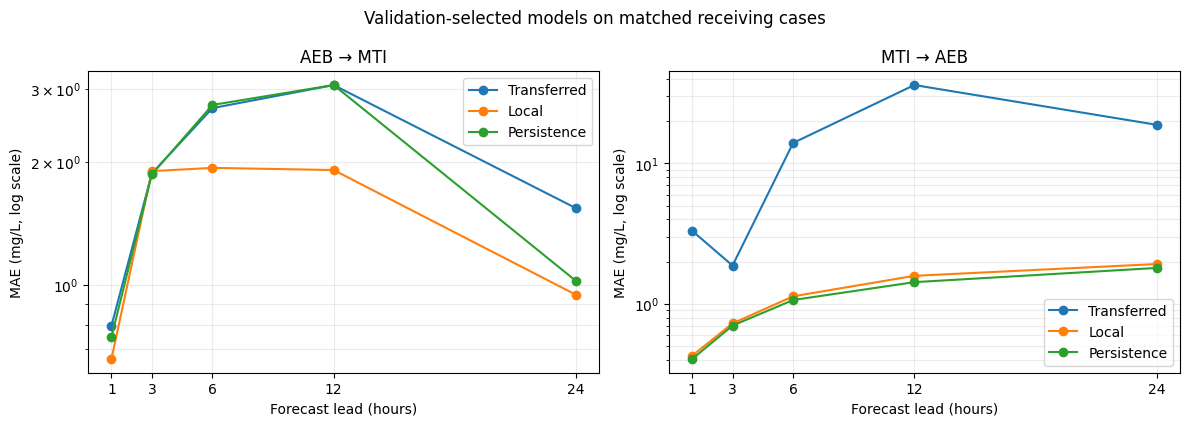

In [8]:
q2_fig, q2_axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True)
for q2_ax, (q2_direction, q2_table) in zip(q2_axes, q2_summary.groupby('Train → evaluate', sort=True)):
    for q2_label, q2_column in [('Transferred', 'Transfer MAE'), ('Local', 'Local MAE'), ('Persistence', 'Persistence MAE')]:
        q2_ax.plot(q2_table['Lead (h)'], q2_table[q2_column], marker='o', label=q2_label)
    q2_ax.set(title=q2_direction, xlabel='Forecast lead (hours)', ylabel='MAE (mg/L, log scale)')
    q2_ax.set_xticks([1, 3, 6, 12, 24])
    q2_ax.set_yscale('log')
    q2_ax.grid(alpha=0.25, which='both')
    q2_ax.legend()
q2_fig.suptitle('Validation-selected models on matched receiving cases')
q2_fig.tight_layout()
plt.close(q2_fig)
q2_fig

In [9]:
q2_transfer_wins = int((q2_summary['Transfer MAE'] < q2_summary['Persistence MAE']).sum())
q2_transfer_local_wins = int((q2_summary['Transfer MAE'] < q2_summary['Local MAE']).sum())
q2_local_wins = q2_summary.assign(local_beats_persistence=q2_summary['Local MAE'] < q2_summary['Persistence MAE'])
print(f'Selected transfer beats persistence: {q2_transfer_wins}/{len(q2_summary)} settings')
print(f'Selected transfer beats selected local ML: {q2_transfer_local_wins}/{len(q2_summary)} settings')
q2_local_wins.groupby('Train → evaluate')['local_beats_persistence'].agg(['sum', 'count'])

Selected transfer beats persistence: 2/10 settings
Selected transfer beats selected local ML: 1/10 settings


,sum,count
Train → evaluate,,
AEB → MTI,4,5
MTI → AEB,0,5


The selected transfer procedure beat persistence in **2 of 10** direction/lead settings and selected local ML in **1 of 10**. Both transfer improvements over persistence occurred when training at AEB and evaluating at MTI: at 6 hours (MAE 2.6995 versus 2.7477) and 12 hours (3.0721 versus 3.0725). The gains were small and uncertain, as the paired intervals show below.

At MTI, selected local models beat persistence at 4 of 5 leads. At AEB, persistence beat the selected local and transferred models at all five leads. These are descriptive counts across related settings, not independent significance tests.

**Same-family check at six hours:** all seven models remain visible, including poor results. Some linear and quadratic transfers produced extreme extrapolation errors. Predictions were not clipped to a physical range; those errors are retained rather than hidden. This table avoids explaining a difference between two selected families solely as a station-transfer effect.

In [10]:
q2_six = q2_main[(q2_main.horizon_hours == 6) &
                 ~q2_main.forecast.isin(['persistence', 'local_selected', 'transferred_selected'])].copy()
q2_six[['Fit scope', 'Model code']] = q2_six.forecast.str.split('_', n=1, expand=True)
q2_six['Model'] = q2_six['Model code'].map(q2_names)
q2_six.pivot(index=['receiver', 'Model'], columns='Fit scope', values='mae').rename_axis(
    index=['Receiving station', 'Model'], columns=None).round(4)

local  transferred
Receiving station Model                                           
AEB               Decision tree                1.1198       5.6751
                  Histogram gradient boosting  1.1842       5.2500
                  Linear (OLS)                 1.1684      13.9578
                  Quadratic Ridge              2.8725    1426.0688
                  Random forest                1.1348       4.8838
                  Ridge                        1.1631      13.9018
                  Two-hidden-layer MLP         3.3736      21.2947
MTI               Decision tree                3.8066       2.6952
                  Histogram gradient boosting  2.8695       2.7346
                  Linear (OLS)                 1.9306       3.1017
                  Quadratic Ridge              2.7509      15.2194
                  Random forest                3.1003       2.6995
                  Ridge                        1.9305       2.9531
                  Two-hidden-layer MLP         3.7115       6.2106

The seven-model chart compares the same family under local and transferred fitting. A logarithmic error axis keeps the extreme failures visible alongside smaller errors. The gray segments connect the two MAE point estimates; they are not uncertainty intervals. The dashed line is persistence at the receiving station.

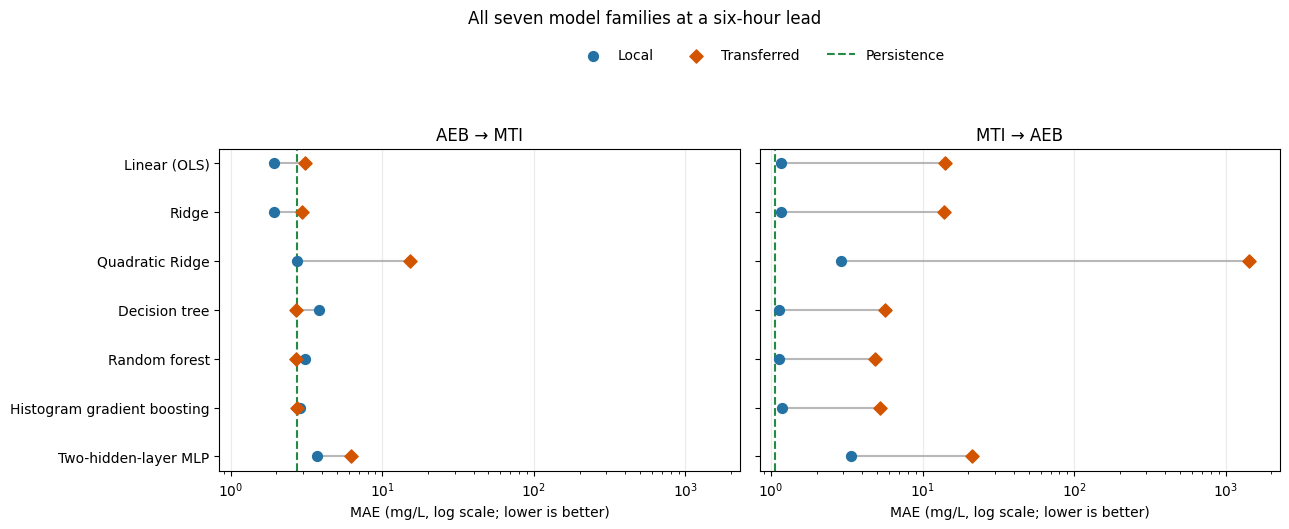

In [11]:
q2_family_fig, q2_family_axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True)
q2_model_order = [q2_names[m] for m in q2_experiment.PRIMARY_MODELS]
q2_positions = np.arange(len(q2_model_order))
q2_family_chart_values = {}
for q2_ax, q2_receiver, q2_source in zip(q2_family_axes, ('MTI', 'AEB'), ('AEB', 'MTI')):
    q2_values = q2_six[q2_six.receiver == q2_receiver].pivot(
        index='Model', columns='Fit scope', values='mae').reindex(q2_model_order)
    assert q2_values.shape == (7, 2) and (q2_values > 0).all().all()
    q2_family_chart_values[q2_receiver] = q2_values.copy()
    q2_ax.hlines(q2_positions, q2_values.min(axis=1), q2_values.max(axis=1),
                 color='#b8b8b8', linewidth=1.5, zorder=1)
    q2_ax.scatter(q2_values['local'], q2_positions, color='#2471a3', marker='o',
                  s=50, label='Local', zorder=3)
    q2_ax.scatter(q2_values['transferred'], q2_positions, color='#d35400', marker='D',
                  s=45, label='Transferred', zorder=3)
    q2_persistence_6h = q2_main.loc[(q2_main.receiver == q2_receiver) &
        (q2_main.horizon_hours == 6) & (q2_main.forecast == 'persistence'), 'mae'].item()
    q2_ax.axvline(q2_persistence_6h, color='#238b45', linestyle='--', linewidth=1.5, label='Persistence')
    q2_ax.set_xscale('log')
    q2_ax.set(title=f'{q2_source} → {q2_receiver}', xlabel='MAE (mg/L, log scale; lower is better)')
    q2_ax.set_yticks(q2_positions, q2_model_order)
    q2_ax.grid(axis='x', which='major', alpha=0.25)
q2_family_axes[0].set_xlim(q2_six.mae.min() * 0.75, q2_six.mae.max() * 1.6)
q2_family_axes[0].invert_yaxis()
q2_family_fig.suptitle('All seven model families at a six-hour lead', y=0.99)
q2_family_fig.legend(*q2_family_axes[0].get_legend_handles_labels(), loc='upper center',
                      bbox_to_anchor=(0.59, 0.94), ncol=3, frameon=False)
q2_family_fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.close(q2_family_fig)
q2_family_fig

**How uncertain are the transfer differences?**

I used paired calendar-block bootstrap intervals with 2,000 resamples and 1-, 2-, 4-, and 7-day blocks. The table and chart show the two-day version for selected transfer versus persistence. A negative difference favors transfer; an interval spanning zero does not establish a reliable improvement or prove equivalence. The intervals are exploratory: their coverage and dependence assumptions are not established, and there is no adjustment for multiple comparisons.

In [12]:
q2_intervals = pd.read_csv(q2_results / 'paired_mae_differences.csv')
q2_ci = q2_intervals.query("policy == 'exclude_negative' and input_set == 'combined' and candidate == 'transferred_selected' and reference == 'persistence' and block_days == 2").copy()
q2_check = q2_ci.merge(q2_summary.assign(receiver=q2_summary['Train → evaluate'].str.split(' → ').str[1]),
                       left_on=['receiver', 'horizon_hours'], right_on=['receiver', 'Lead (h)'], validate='one_to_one')
np.testing.assert_allclose(q2_check.mae_difference, q2_check['Transfer MAE'] - q2_check['Persistence MAE'], atol=1e-12)
q2_ci[['source', 'receiver', 'horizon_hours', 'mae_difference', 'ci_low', 'ci_high']].rename(columns={
    'source': 'Training station', 'receiver': 'Receiving station', 'horizon_hours': 'Lead (h)',
    'mae_difference': 'Transfer − persistence MAE', 'ci_low': '95% lower', 'ci_high': '95% upper'}).round(5)

,Training station,Receiving station,Lead (h),Transfer − persistence MAE,95% lower,95% upper
61,MTI,AEB,1,2.90811,2.63076,3.17753
149,MTI,AEB,3,1.17531,0.84283,1.60677
237,MTI,AEB,6,12.88929,11.09144,14.52454
325,MTI,AEB,12,34.57153,30.56310,38.10180
413,MTI,AEB,24,16.97081,14.67036,19.07410
501,AEB,MTI,1,0.04838,0.03493,0.06234
589,AEB,MTI,3,0.00969,-0.01480,0.03269
677,AEB,MTI,6,-0.04821,-0.09885,0.00318
765,AEB,MTI,12,-0.00044,-0.04275,0.04582
853,AEB,MTI,24,0.51604,0.37087,0.64771


The confidence-interval chart uses a separate linear x-axis range for each direction because the error differences have very different magnitudes. The dashed zero line means equal point MAE; points to its left favor transfer. Both small AEB-to-MTI improvements have intervals crossing zero.

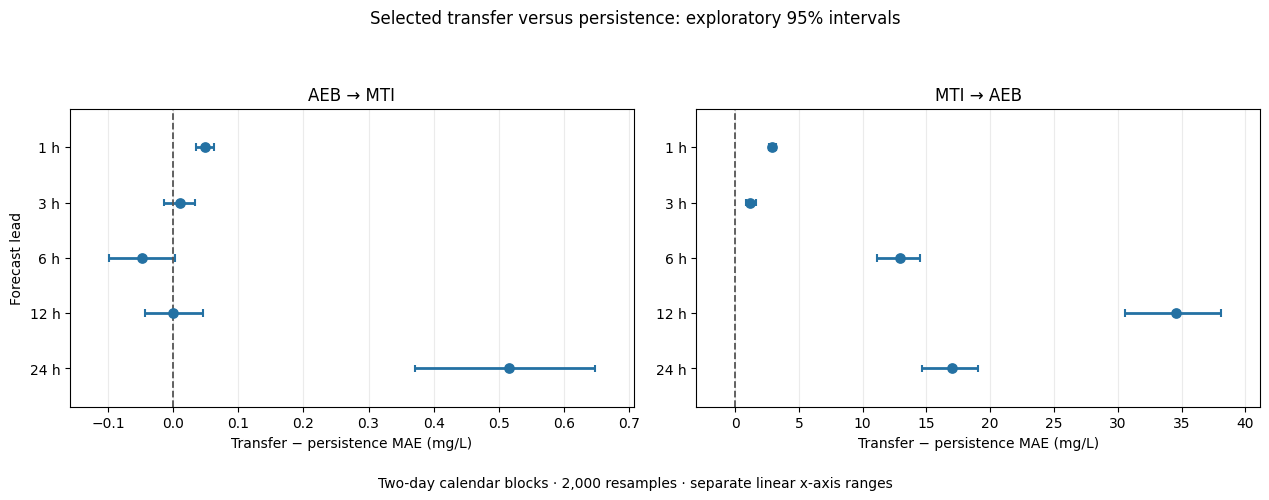

In [13]:
q2_ci_fig, q2_ci_axes = plt.subplots(1, 2, figsize=(12.8, 4.9), sharey=True)
q2_ci_chart_values = {}
for q2_ax, q2_receiver, q2_source in zip(q2_ci_axes, ('MTI', 'AEB'), ('AEB', 'MTI')):
    q2_points = q2_ci[q2_ci.receiver == q2_receiver].sort_values('horizon_hours')
    assert len(q2_points) == 5 and (q2_points.ci_low <= q2_points.ci_high).all()
    q2_ci_chart_values[q2_receiver] = q2_points[
        ['horizon_hours', 'mae_difference', 'ci_low', 'ci_high']].copy()
    q2_ypos = np.arange(len(q2_points))
    q2_ax.hlines(q2_ypos, q2_points.ci_low, q2_points.ci_high, color='#2471a3', linewidth=2)
    q2_ax.vlines(q2_points.ci_low, q2_ypos - 0.07, q2_ypos + 0.07, color='#2471a3')
    q2_ax.vlines(q2_points.ci_high, q2_ypos - 0.07, q2_ypos + 0.07, color='#2471a3')
    q2_ax.scatter(q2_points.mae_difference, q2_ypos, color='#2471a3', s=45, zorder=3)
    q2_ax.axvline(0, color='#555555', linestyle='--', linewidth=1.3)
    q2_ax.set(title=f'{q2_source} → {q2_receiver}', xlabel='Transfer − persistence MAE (mg/L)')
    q2_ax.set_yticks(q2_ypos, [f'{h} h' for h in q2_points.horizon_hours])
    q2_ax.grid(axis='x', alpha=0.25)
    q2_ax.margins(x=0.08, y=0.15)
q2_ci_axes[0].set_ylabel('Forecast lead')
q2_ci_axes[0].invert_yaxis()
q2_ci_axes[1].tick_params(labelleft=True)
q2_ci_fig.suptitle('Selected transfer versus persistence: exploratory 95% intervals', y=0.99)
q2_ci_fig.text(0.5, 0.015, 'Two-day calendar blocks · 2,000 resamples · separate linear x-axis ranges',
                ha='center', fontsize=10)
q2_ci_fig.tight_layout(rect=(0, 0.06, 1, 0.93))
plt.close(q2_ci_fig)
q2_ci_fig

**Processing sensitivity, training warnings, and collinearity**

The next table compares negative-value exclusion with independently tuned zero-clipping **on exactly the same receiving cases**. Comparing unmatched scores would mix a model difference with a change in evaluation cases. Policy changes can affect histories, training support, parameter selection, and the chosen family; they are not just a final prediction adjustment.

In [14]:
q2_policy = pd.read_csv(q2_results / 'cleaning_policy_comparison.csv')
q2_policy_selected = q2_policy.query("input_set == 'combined' and forecast in ['transferred_selected', 'local_selected']")
q2_policy_selected[['receiver', 'horizon_hours', 'forecast', 'common_n',
                     'mae_exclude_negative', 'mae_clip_zero_on_common']].round(4)

,receiver,horizon_hours,forecast,common_n,mae_exclude_negative,mae_clip_zero_on_common
15,AEB,1,local_selected,2167,0.4293,0.4329
16,AEB,1,transferred_selected,2167,3.3149,3.2579
39,AEB,3,local_selected,2089,0.7283,0.7570
40,AEB,3,transferred_selected,2089,1.8779,1.9866
63,AEB,6,local_selected,2013,1.1348,1.1218
64,AEB,6,transferred_selected,2013,13.9578,14.3510
87,AEB,12,local_selected,1916,1.5868,1.4811
88,AEB,12,transferred_selected,1916,36.0022,36.4773
111,AEB,24,local_selected,1675,1.9244,1.9995
112,AEB,24,transferred_selected,1675,18.7762,18.7447


In [15]:
q2_diagnostics = pd.read_csv(q2_results / 'fit_diagnostics.csv')
q2_neural_fits = q2_diagnostics.query("policy == 'exclude_negative' and input_set == 'combined' and model == 'mlp' and stage == 'evaluation_fit'").copy()
q2_warning_flags = q2_neural_fits.convergence_warning.astype(str).str.lower().eq('true')
print(f'Primary final MLP fits with convergence warnings: {int(q2_warning_flags.sum())}/{len(q2_neural_fits)}')
q2_neural_fits[['source', 'horizon_hours', 'n_iter', 'convergence_warning']]

Primary final MLP fits with convergence warnings: 8/10


,source,horizon_hours,n_iter,convergence_warning
45,AEB,1,400.0,True
105,AEB,3,400.0,True
165,AEB,6,400.0,True
225,AEB,12,400.0,True
285,AEB,24,400.0,True
345,MTI,1,400.0,True
405,MTI,3,400.0,True
465,MTI,6,394.0,False
525,MTI,12,319.0,False
585,MTI,24,400.0,True


The primary network used a 400-epoch cap and one random seed. Convergence warnings limit conclusions about an optimized neural model; a larger search or different training budget is a separate experiment. I do not interpret a weak primary MLP score as proof that neural networks cannot transfer.

I also checked the actual six-hour source-training feature matrices. Full rank does not imply weak multicollinearity. The diagnostic below computes maximum VIF after training-only median imputation and standardization. Ridge helps regularize correlated inputs, but it does not ensure stable extrapolation at a different station.

In [16]:
q2_collinearity = []
with threadpool_limits(limits=2):
    for q2_station, q2_station_data in q2_data.items():
        _, _, q2_tr, _ = q2_core.split_masks(q2_station_data, 6, q2_experiment.CUTOFF)
        q2_x = q2_features[q2_station].loc[q2_tr]
        q2_filled = q2_x.fillna(q2_x.median())
        q2_z = (q2_filled - q2_filled.mean()) / q2_filled.std(ddof=0)
        q2_design = np.column_stack([np.ones(len(q2_z)), q2_z.to_numpy()])
        q2_vifs = []
        for q2_column in q2_z:
            q2_other, q2_response = q2_z.drop(columns=q2_column).to_numpy(), q2_z[q2_column].to_numpy()
            q2_residual = q2_response - q2_other @ np.linalg.lstsq(q2_other, q2_response, rcond=None)[0]
            q2_vifs.append(float(np.sum(q2_response ** 2) / np.sum(q2_residual ** 2)))
        q2_collinearity.append({'Source': q2_station, 'Fit cases': len(q2_z),
                                'Rank including intercept': int(np.linalg.matrix_rank(q2_design)),
                                'Full rank': q2_design.shape[1], 'Maximum VIF': max(q2_vifs)})
pd.DataFrame(q2_collinearity).round(2)

,Source,Fit cases,Rank including intercept,Full rank,Maximum VIF
0,AEB,7861,25,25,2039.33
1,MTI,12208,25,25,237.91


### 13.4 Conclusion and limitations

For these stations and this season, **I would not assume that a model trained at one station will work well at the other without local evaluation**. Transfer performance depended strongly on direction and lead time, and the two small improvements over persistence had intervals spanning zero.

This also does **not** show that each station must have its own ML model. Persistence was stronger than selected local ML at every tested lead at AEB. Local training was more useful at MTI. A station-specific model should therefore be justified against persistence rather than assumed necessary.

This is a controlled, exploratory transfer comparison for two monitored sites in one April–October season. Both evaluation periods had been viewed in the earlier analysis, so these results are not a fresh confirmatory test. Unequal training support, missingness, negative-value assumptions, correlated predictors, coarse tuning, and the primary neural training budget limit the conclusions. Measurement availability at each forecast origin is assumed; telemetry delays and an operational error tolerance were not modeled.

Additional stations or a separately reserved year would be needed to assess broader generalization. Pooled training or limited local calibration could be future experiments; neither is demonstrated here. I am not claiming that DO forecasting or spatial transfer itself is new.